
# Offshore Oil & Gas Production Surveillance and Flow Assurance Analysis

## Project Overview

This project focuses on analysing historical offshore oil and gas production data from the Equinor Volve field using Python.

The analysis will examine production performance, water production, gas-oil ratio, choke performance and production decline.

## Project Objectives

1. Evaluate individual well production performance.
2. Monitor changes in water cut and gas-oil ratio.
3. Identify unusual production behaviour.
4. Analyse production decline and forecast future oil production.
5. Prepare a cleaned dataset for further analysis in Power BI.


In [231]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("All libraries imported successfully.")

All libraries imported successfully.



## 1. Data Acquisition and Initial Exploration

The first stage involves importing the Volve production dataset into Python and examining its structure.

The dataset contains historical daily production records from the Volve offshore oil field operated by Equinor.

The initial exploration will focus on identifying the available variables, understanding their data types, checking data completeness and examining the production records available for individual wellbores.

This stage provides the foundation for subsequent data cleaning and engineering analysis.


In [232]:
df = pd.read_excel(
    r"C:\Users\DELL\Documents\Volve_Production_Survelliance\Volve production data.xlsx",
    sheet_name="Daily Production Data"
)

In [233]:
df.head()

,DATEPRD,WELL_BORE_CODE,NPD_WELL_BORE_CODE,NPD_WELL_BORE_NAME,NPD_FIELD_CODE,NPD_FIELD_NAME,NPD_FACILITY_CODE,NPD_FACILITY_NAME,ON_STREAM_HRS,AVG_DOWNHOLE_PRESSURE,...,AVG_CHOKE_UOM,AVG_WHP_P,AVG_WHT_P,DP_CHOKE_SIZE,BORE_OIL_VOL,BORE_GAS_VOL,BORE_WAT_VOL,BORE_WI_VOL,FLOW_KIND,WELL_TYPE
0,2014-04-07,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,0.00000,...,%,0.00000,0.00000,0.00000,0.0,0.0,0.0,NaN,production,WI
1,2014-04-08,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,NaN,...,%,0.00000,0.00000,0.00000,0.0,0.0,0.0,NaN,production,OP
2,2014-04-09,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,NaN,...,%,0.00000,0.00000,0.00000,0.0,0.0,0.0,NaN,production,OP
3,2014-04-10,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,NaN,...,%,0.00000,0.00000,0.00000,0.0,0.0,0.0,NaN,production,OP
4,2014-04-11,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,310.37614,...,%,33.09788,10.47992,33.07195,0.0,0.0,0.0,NaN,production,OP


In [234]:
df.shape

(15634, 24)

In [235]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15634 entries, 0 to 15633
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   DATEPRD                   15634 non-null  datetime64[us]
 1   WELL_BORE_CODE            15634 non-null  str           
 2   NPD_WELL_BORE_CODE        15634 non-null  int64         
 3   NPD_WELL_BORE_NAME        15634 non-null  str           
 4   NPD_FIELD_CODE            15634 non-null  int64         
 5   NPD_FIELD_NAME            15634 non-null  str           
 6   NPD_FACILITY_CODE         15634 non-null  int64         
 7   NPD_FACILITY_NAME         15634 non-null  str           
 8   ON_STREAM_HRS             15349 non-null  float64       
 9   AVG_DOWNHOLE_PRESSURE     8980 non-null   float64       
 10  AVG_DOWNHOLE_TEMPERATURE  8980 non-null   float64       
 11  AVG_DP_TUBING             8980 non-null   float64       
 12  AVG_ANNULUS_PRESS         789

In [236]:
df.isnull().sum()

DATEPRD                        0
WELL_BORE_CODE                 0
NPD_WELL_BORE_CODE             0
NPD_WELL_BORE_NAME             0
NPD_FIELD_CODE                 0
NPD_FIELD_NAME                 0
NPD_FACILITY_CODE              0
NPD_FACILITY_NAME              0
ON_STREAM_HRS                285
AVG_DOWNHOLE_PRESSURE       6654
AVG_DOWNHOLE_TEMPERATURE    6654
AVG_DP_TUBING               6654
AVG_ANNULUS_PRESS           7744
AVG_CHOKE_SIZE_P            6715
AVG_CHOKE_UOM               6473
AVG_WHP_P                   6479
AVG_WHT_P                   6488
DP_CHOKE_SIZE                294
BORE_OIL_VOL                6473
BORE_GAS_VOL                6473
BORE_WAT_VOL                6473
BORE_WI_VOL                 9928
FLOW_KIND                      0
WELL_TYPE                      0
dtype: int64

In [237]:
df['NPD_WELL_BORE_NAME'].nunique()

7

In [238]:
df['NPD_WELL_BORE_NAME'].value_counts()

NPD_WELL_BORE_NAME
15/9-F-4       3327
15/9-F-5       3306
15/9-F-12      3056
15/9-F-14      3056
15/9-F-11      1165
15/9-F-15 D     978
15/9-F-1 C      746
Name: count, dtype: int64

In [239]:
df['FLOW_KIND'].value_counts()

FLOW_KIND
production    9161
injection     6473
Name: count, dtype: int64

In [240]:
df['WELL_TYPE'].value_counts()

WELL_TYPE
OP    9143
WI    6491
Name: count, dtype: int64

In [241]:
df['DATEPRD'].min()


Timestamp('2007-09-01 00:00:00')

In [242]:
df['DATEPRD'].max()

Timestamp('2016-12-01 00:00:00')

## Section Summary

The Volve daily production dataset was successfully imported into Python for preliminary exploration. The dataset contains 15,634 records and 24 columns, covering the period from September 2007 to December 2016.

The dataset contains seven unique wellbores, with varying numbers of production records across the wells. It also includes two flow categories: production (9,161 records) and injection (6,473 records), as well as two well types: OP and WI.

Initial inspection revealed missing values in several operational and production variables, particularly pressure, temperature and fluid volume measurements. The production volume columns each contain 9,161 non-null entries, while the injection volume column contains 5,706 non-null entries.

These observations provide an understanding of the dataset's structure and highlight areas requiring further investigation during data cleaning and preparation.

## 2. Data Cleaning and Preparation

This stage involves preparing the Volve production dataset for engineering analysis. The initial exploration revealed missing values across several production and operational variables, which must be investigated before further analysis.

The dataset will be examined for missing values, inconsistencies and records that require special treatment. Production and injection records will also be distinguished to ensure that subsequent engineering calculations are performed on the appropriate data.

The objective is to obtain a reliable and well-structured dataset for production performance analysis.

In [243]:
df_clean = df.copy()

In [244]:
df_clean.isnull().sum()

DATEPRD                        0
WELL_BORE_CODE                 0
NPD_WELL_BORE_CODE             0
NPD_WELL_BORE_NAME             0
NPD_FIELD_CODE                 0
NPD_FIELD_NAME                 0
NPD_FACILITY_CODE              0
NPD_FACILITY_NAME              0
ON_STREAM_HRS                285
AVG_DOWNHOLE_PRESSURE       6654
AVG_DOWNHOLE_TEMPERATURE    6654
AVG_DP_TUBING               6654
AVG_ANNULUS_PRESS           7744
AVG_CHOKE_SIZE_P            6715
AVG_CHOKE_UOM               6473
AVG_WHP_P                   6479
AVG_WHT_P                   6488
DP_CHOKE_SIZE                294
BORE_OIL_VOL                6473
BORE_GAS_VOL                6473
BORE_WAT_VOL                6473
BORE_WI_VOL                 9928
FLOW_KIND                      0
WELL_TYPE                      0
dtype: int64

In [245]:
df_clean['FLOW_KIND'] == 'production'

0         True
1         True
2         True
3         True
4         True
         ...  
15629     True
15630     True
15631     True
15632     True
15633    False
Name: FLOW_KIND, Length: 15634, dtype: bool

In [246]:
df_production = df_clean[df_clean['FLOW_KIND'] == 'production']

In [247]:
df_production.shape

(9161, 24)

In [248]:
df_production.isnull().sum()

DATEPRD                        0
WELL_BORE_CODE                 0
NPD_WELL_BORE_CODE             0
NPD_WELL_BORE_NAME             0
NPD_FIELD_CODE                 0
NPD_FIELD_NAME                 0
NPD_FACILITY_CODE              0
NPD_FACILITY_NAME              0
ON_STREAM_HRS                  0
AVG_DOWNHOLE_PRESSURE        181
AVG_DOWNHOLE_TEMPERATURE     181
AVG_DP_TUBING                181
AVG_ANNULUS_PRESS           1271
AVG_CHOKE_SIZE_P             242
AVG_CHOKE_UOM                  0
AVG_WHP_P                      6
AVG_WHT_P                     15
DP_CHOKE_SIZE                  6
BORE_OIL_VOL                   0
BORE_GAS_VOL                   0
BORE_WAT_VOL                   0
BORE_WI_VOL                 9146
FLOW_KIND                      0
WELL_TYPE                      0
dtype: int64

In [249]:
df_production['NPD_WELL_BORE_NAME'].value_counts()

NPD_WELL_BORE_NAME
15/9-F-12      3056
15/9-F-14      3056
15/9-F-11      1165
15/9-F-15 D     978
15/9-F-1 C      746
15/9-F-5        160
Name: count, dtype: int64

In [250]:
df_clean[df_clean['NPD_WELL_BORE_NAME'] == '15/9-F-4']['FLOW_KIND'].value_counts()

FLOW_KIND
injection    3327
Name: count, dtype: int64

In [251]:
# This checks how the records for wellbore 15/9-F-5 are distributed between production and injection.
df_clean[df_clean['NPD_WELL_BORE_NAME'] == '15/9-F-5']['FLOW_KIND'].value_counts()

FLOW_KIND
injection     3146
production     160
Name: count, dtype: int64

In [252]:
# This shows the number of production and injection records available for each wellbore.
pd.crosstab(df_clean['NPD_WELL_BORE_NAME'], df_clean['FLOW_KIND'])

FLOW_KIND,injection,production
NPD_WELL_BORE_NAME,,
15/9-F-1 C,0,746
15/9-F-11,0,1165
15/9-F-12,0,3056
15/9-F-14,0,3056
15/9-F-15 D,0,978
15/9-F-4,3327,0
15/9-F-5,3146,160


In [253]:
# This compares the WELL_TYPE and FLOW_KIND columns to identify any differences in their classifications.
pd.crosstab(df_clean['WELL_TYPE'], df_clean['FLOW_KIND'])

FLOW_KIND,injection,production
WELL_TYPE,,
OP,0,9143
WI,6473,18


In [254]:
# This identifies the first and last production dates and the number of records available for each wellbore.
df_production.groupby('NPD_WELL_BORE_NAME')['DATEPRD'].agg(['min', 'max', 'count'])

,min,max,count
NPD_WELL_BORE_NAME,,,
15/9-F-1 C,2014-04-07,2016-04-21,746
15/9-F-11,2013-07-08,2016-09-17,1165
15/9-F-12,2008-02-12,2016-09-17,3056
15/9-F-14,2008-02-12,2016-09-17,3056
15/9-F-15 D,2014-01-12,2016-09-17,978
15/9-F-5,2016-04-11,2016-09-17,160


In [255]:
# This examines the well types within the production records to identify wellbores with inconsistent classifications.
pd.crosstab(df_production['NPD_WELL_BORE_NAME'], df_production['WELL_TYPE'])

WELL_TYPE,OP,WI
NPD_WELL_BORE_NAME,,
15/9-F-1 C,744,2
15/9-F-11,1165,0
15/9-F-12,3056,0
15/9-F-14,3056,0
15/9-F-15 D,978,0
15/9-F-5,144,16


In [256]:
# This identifies production records with zero operating hours, which may represent periods of well inactivity or downtime.
df_production[df_production['ON_STREAM_HRS'] == 0].shape

(1141, 24)

In [257]:
# This checks whether any complete rows are repeated in the production dataset.
df_production.duplicated().sum()

np.int64(0)

In [258]:
# This checks whether a wellbore has more than one production record for the same date.
df_production.duplicated(
    subset=['NPD_WELL_BORE_NAME', 'DATEPRD']
).sum()

np.int64(0)

In [259]:
# This identifies records with negative water production values for further data-quality investigation.
df_production[df_production['BORE_WAT_VOL'] < 0][
    ['DATEPRD', 'NPD_WELL_BORE_NAME', 'ON_STREAM_HRS',
     'BORE_OIL_VOL', 'BORE_GAS_VOL', 'BORE_WAT_VOL']
]

,DATEPRD,NPD_WELL_BORE_NAME,ON_STREAM_HRS,BORE_OIL_VOL,BORE_GAS_VOL,BORE_WAT_VOL
1982,2008-04-23,15/9-F-12,24.000,2735.53,422115.01,-14.19
3502,2012-08-13,15/9-F-12,0.625,632.96,12123.37,-457.84
5350,2009-03-03,15/9-F-14,24.000,4339.13,616094.56,-0.95
6558,2012-08-13,15/9-F-14,0.625,202.53,3754.12,-59.19


In [260]:
# This identifies daily production records with operating hours above 24 for further investigation.
df_production[df_production['ON_STREAM_HRS'] > 24][
    ['DATEPRD', 'NPD_WELL_BORE_NAME', 'ON_STREAM_HRS']
]

,DATEPRD,NPD_WELL_BORE_NAME,ON_STREAM_HRS
202,2014-10-26,15/9-F-1 C,25.00000
856,2013-10-27,15/9-F-11,24.30839
1218,2014-10-26,15/9-F-11,25.00000
2166,2008-10-26,15/9-F-12,25.00000
2527,2009-10-25,15/9-F-12,24.83333
2891,2010-10-31,15/9-F-12,25.00000
3912,2013-10-27,15/9-F-12,24.14167
4274,2014-10-26,15/9-F-12,25.00000
5222,2008-10-26,15/9-F-14,25.00000
5583,2009-10-25,15/9-F-14,24.50000


In [261]:
# This summarizes the missing values and their percentages across the main operational measurement columns.
operational_columns = [
    'AVG_DOWNHOLE_PRESSURE',
    'AVG_DOWNHOLE_TEMPERATURE',
    'AVG_DP_TUBING',
    'AVG_ANNULUS_PRESS',
    'AVG_CHOKE_SIZE_P',
    'AVG_WHP_P',
    'AVG_WHT_P',
    'DP_CHOKE_SIZE'
]

missing_summary = pd.DataFrame({
    'Missing Values': df_production[operational_columns].isnull().sum(),
    'Missing (%)': (df_production[operational_columns].isnull().mean() * 100).round(2)
})

missing_summary

,Missing Values,Missing (%)
AVG_DOWNHOLE_PRESSURE,181,1.98
AVG_DOWNHOLE_TEMPERATURE,181,1.98
AVG_DP_TUBING,181,1.98
AVG_ANNULUS_PRESS,1271,13.87
AVG_CHOKE_SIZE_P,242,2.64
AVG_WHP_P,6,0.07
AVG_WHT_P,15,0.16
DP_CHOKE_SIZE,6,0.07


In [262]:
# This identifies how many operational measurements are missing for each individual wellbore.
missing_by_well = df_production.groupby('NPD_WELL_BORE_NAME')[operational_columns].apply(
    lambda x: x.isnull().sum()
)

missing_by_well

,AVG_DOWNHOLE_PRESSURE,AVG_DOWNHOLE_TEMPERATURE,AVG_DP_TUBING,AVG_ANNULUS_PRESS,AVG_CHOKE_SIZE_P,AVG_WHP_P,AVG_WHT_P,DP_CHOKE_SIZE
NPD_WELL_BORE_NAME,,,,,,,,
15/9-F-1 C,3,3,3,729,0,0,0,0
15/9-F-11,6,6,6,6,2,6,6,6
15/9-F-12,6,6,6,13,44,0,0,0
15/9-F-14,6,6,6,523,196,0,0,0
15/9-F-15 D,0,0,0,0,0,0,0,0
15/9-F-5,160,160,160,0,0,0,9,0


In [263]:
# This checks the availability of selected pressure and temperature measurements for wellbore 15/9-F-5.
df_production[df_production['NPD_WELL_BORE_NAME'] == '15/9-F-5'][
    ['AVG_DOWNHOLE_PRESSURE', 'AVG_DOWNHOLE_TEMPERATURE', 'AVG_DP_TUBING',
     'AVG_ANNULUS_PRESS', 'AVG_CHOKE_SIZE_P']
].isnull().sum()

AVG_DOWNHOLE_PRESSURE       160
AVG_DOWNHOLE_TEMPERATURE    160
AVG_DP_TUBING               160
AVG_ANNULUS_PRESS             0
AVG_CHOKE_SIZE_P              0
dtype: int64

In [264]:
# This verifies that the operating hours and main produced-fluid volume measurements are complete.
df_production[
    ['ON_STREAM_HRS', 'BORE_OIL_VOL', 'BORE_GAS_VOL', 'BORE_WAT_VOL']
].isnull().sum()

ON_STREAM_HRS    0
BORE_OIL_VOL     0
BORE_GAS_VOL     0
BORE_WAT_VOL     0
dtype: int64

In [265]:
# This checks the missing injection volume measurements within the production records.
df_production['BORE_WI_VOL'].isnull().sum()

np.int64(9146)

In [266]:
# This creates a separate working copy of the production records for data preparation and subsequent engineering analysis.
df_production_clean = df_production.copy()

In [267]:
# This checks the dimensions of the new production analysis dataset.
df_production_clean.shape

(9161, 24)

In [268]:
# This identifies records with negative water production volumes for separate treatment during engineering calculations.
df_production_clean['NEGATIVE_WATER_FLAG'] = df_production_clean['BORE_WAT_VOL'] < 0

In [269]:
# This counts the records identified as having negative water production volumes.
df_production_clean['NEGATIVE_WATER_FLAG'].sum()

np.int64(4)

In [270]:
# This identifies daily production records with operating hours exceeding 24.
df_production_clean['ON_STREAM_GT_24_FLAG'] = df_production_clean['ON_STREAM_HRS'] > 24

In [271]:
# This counts the records with operating hours above 24.
df_production_clean['ON_STREAM_GT_24_FLAG'].sum()

np.int64(13)

In [272]:
# This creates a calculation column in which negative water volume measurements are treated as missing values.
df_production_clean['BORE_WAT_VOL_ANALYSIS'] = df_production_clean['BORE_WAT_VOL'].where(
    df_production_clean['BORE_WAT_VOL'] >= 0
)

In [273]:
# This verifies that the four negative water volume measurements have been excluded from the calculation column.
df_production_clean['BORE_WAT_VOL_ANALYSIS'].isnull().sum()

np.int64(4)

In [274]:
# This verifies the final dataset dimensions, zero-operating-hour records and data-quality flags.
print("Dataset shape:", df_production_clean.shape)
print("Zero operating-hour records:", (df_production_clean['ON_STREAM_HRS'] == 0).sum())
print("Negative water volume records:", df_production_clean['NEGATIVE_WATER_FLAG'].sum())
print("Operating hours above 24:", df_production_clean['ON_STREAM_GT_24_FLAG'].sum())

Dataset shape: (9161, 27)
Zero operating-hour records: 1141
Negative water volume records: 4
Operating hours above 24: 13


## Section Summary

The data cleaning and preparation stage focused on investigating missing values, checking record consistency and preparing the Volve production dataset for subsequent engineering analysis.

The original dataset was preserved, while a separate production subset containing 9,161 records was created. The investigation identified six producing wellbores, with 15/9-F-4 containing only injection records and 15/9-F-5 having both production and injection records.

The main production variables (`ON_STREAM_HRS`, `BORE_OIL_VOL`, `BORE_GAS_VOL` and `BORE_WAT_VOL`) contained no missing values in the production subset. However, several operational measurements, particularly downhole pressure, temperature and annulus pressure, contained missing values. These were investigated across the individual wellbores. No arbitrary values were introduced to fill the missing measurements.

Further checks identified 1,141 records with zero operating hours, 13 records with operating hours exceeding 24, and four records with negative water production volumes. These records were retained rather than deleted because they may provide useful information for operational and data-quality investigations.

A separate dataset, `df_production_clean`, was created for subsequent analysis. Three additional columns were introduced: `NEGATIVE_WATER_FLAG`, `ON_STREAM_GT_24_FLAG` and `BORE_WAT_VOL_ANALYSIS`. These help identify unusual measurements and provide a separate water volume column for calculations without altering the original data.

The final prepared dataset contains 9,161 records and 27 columns. It preserves the original production measurements while identifying records requiring special consideration.

This dataset provides the foundation for calculating production performance indicators and investigating the operational behaviour of the producing wellbores.

## 3. Production Performance Analysis

This stage involves evaluating the production performance of the Volve producing wellbores using key engineering indicators.

The analysis will focus on calculating total liquid production, water cut, gas-oil ratio (GOR) and operating efficiency.

These indicators will be used to assess fluid production characteristics and compare the performance of individual wellbores.

The results will be summarised in a table to provide a clear overview of production performance across the field.

In [275]:
# This creates a separate copy of the prepared production dataset for performance analysis.
df_analysis = df_production_clean.copy()

Total liquid production is the combined volume of oil and water produced.

$$
Q_L = Q_O + Q_W
$$


Water cut represents the percentage of total liquid production made up of water.

$$
WC(\%) = \frac{Q_W}{Q_O + Q_W} \times 100
$$


In [276]:
# This calculates total liquid production by adding oil and valid water production volumes.
df_analysis['TOTAL_LIQUID'] = (
    df_analysis['BORE_OIL_VOL'] +
    df_analysis['BORE_WAT_VOL_ANALYSIS']
)

In [277]:
# This calculates the percentage of water in the total liquid production.
df_analysis['WATER_CUT'] = (
    df_analysis['BORE_WAT_VOL_ANALYSIS'] /
    df_analysis['TOTAL_LIQUID']
) * 100

# This excludes records with zero or invalid total liquid production.
df_analysis.loc[
    df_analysis['TOTAL_LIQUID'] <= 0, 'WATER_CUT'
] = np.nan

GOR measures the volume of gas produced relative to the volume of oil produced.

$$
GOR = \frac{Q_G}{Q_O}
$$


In [278]:
# This calculates the gas-oil ratio using gas and oil production volumes.
df_analysis['GOR'] = (
    df_analysis['BORE_GAS_VOL'] /
    df_analysis['BORE_OIL_VOL']
)

# This excludes records with zero or negative oil production.
df_analysis.loc[
    df_analysis['BORE_OIL_VOL'] <= 0, 'GOR'
] = np.nan

Operating efficiency measures the percentage of the 24-hour day during which a well was operating.

$$
OE(\%) = \frac{\text{ON STREAM HOURS}}{24} \times 100
$$


In [279]:
# This calculates the percentage of the daily 24-hour period during which each well was operating.
df_analysis['OPERATING_EFFICIENCY'] = (
    df_analysis['ON_STREAM_HRS'] / 24
) * 100

In [280]:
# This displays the calculated production indicators in a cleaner table format.
df_analysis[
    ['NPD_WELL_BORE_NAME', 'DATEPRD',
     'TOTAL_LIQUID', 'WATER_CUT',
     'GOR', 'OPERATING_EFFICIENCY']
].head()

,NPD_WELL_BORE_NAME,DATEPRD,TOTAL_LIQUID,WATER_CUT,GOR,OPERATING_EFFICIENCY
0,15/9-F-1 C,2014-04-07,0.0,NaN,NaN,0.0
1,15/9-F-1 C,2014-04-08,0.0,NaN,NaN,0.0
2,15/9-F-1 C,2014-04-09,0.0,NaN,NaN,0.0
3,15/9-F-1 C,2014-04-10,0.0,NaN,NaN,0.0
4,15/9-F-1 C,2014-04-11,0.0,NaN,NaN,0.0


In [281]:
# This provides descriptive statistics for the four calculated production performance indicators.
df_analysis[
    ['TOTAL_LIQUID', 'WATER_CUT',
     'GOR', 'OPERATING_EFFICIENCY']
].describe()

,TOTAL_LIQUID,WATER_CUT,GOR,OPERATING_EFFICIENCY
count,9157.000000,8006.000000,8008.000000,9161.000000
mean,2768.186194,53.590288,151.960542,84.036337
std,2038.744132,34.326319,16.449967,34.555839
min,0.000000,0.000000,18.536118,0.000000
25%,646.240000,15.924217,145.826418,100.000000
50%,3066.290000,63.807948,151.429372,100.000000
75%,4717.650000,84.966296,156.810801,100.000000
max,13065.460000,100.000000,1110.185309,104.166667


In [282]:
# This checks the number of missing values in each calculated production indicator.
df_analysis[
    ['TOTAL_LIQUID', 'WATER_CUT',
     'GOR', 'OPERATING_EFFICIENCY']
].isnull().sum()

TOTAL_LIQUID               4
WATER_CUT               1155
GOR                     1153
OPERATING_EFFICIENCY       0
dtype: int64

In [283]:
# This groups the production records by wellbore to enable performance comparison.
well_summary = df_analysis.groupby('NPD_WELL_BORE_NAME')

In [284]:
# This summarises cumulative liquid production and average water cut, GOR and operating efficiency for each wellbore.
well_summary = df_analysis.groupby('NPD_WELL_BORE_NAME').agg(
    TOTAL_LIQUID=('TOTAL_LIQUID', 'sum'),
    WATER_CUT=('WATER_CUT', 'mean'),
    GOR=('GOR', 'mean'),
    OPERATING_EFFICIENCY=('OPERATING_EFFICIENCY', 'mean')
)

well_summary

,TOTAL_LIQUID,WATER_CUT,GOR,OPERATING_EFFICIENCY
NPD_WELL_BORE_NAME,,,,
15/9-F-1 C,385011.72,51.001531,151.274591,55.761468
15/9-F-11,2238655.37,38.277389,154.026691,93.012218
15/9-F-12,11410033.46,59.582480,152.166312,88.901709
15/9-F-14,11059001.61,65.120413,150.564250,85.588017
15/9-F-15 D,200884.96,19.312997,152.231957,75.940835
15/9-F-5,54693.86,24.345057,159.596498,77.430339


In [285]:
# This rounds the summary values to two decimal places for easier interpretation and presentation.
well_summary = well_summary.round(2)

well_summary

,TOTAL_LIQUID,WATER_CUT,GOR,OPERATING_EFFICIENCY
NPD_WELL_BORE_NAME,,,,
15/9-F-1 C,385011.72,51.00,151.27,55.76
15/9-F-11,2238655.37,38.28,154.03,93.01
15/9-F-12,11410033.46,59.58,152.17,88.90
15/9-F-14,11059001.61,65.12,150.56,85.59
15/9-F-15 D,200884.96,19.31,152.23,75.94
15/9-F-5,54693.86,24.35,159.60,77.43


## Section Summary

The production performance analysis involved calculating four key engineering indicators: total liquid production, water cut, gas-oil ratio (GOR) and operating efficiency.

The calculated indicators were used to evaluate the fluid production characteristics and operating performance of the six producing wellbores.

A summary table was generated using the wellbore classification to compare cumulative liquid production and average water cut, GOR and operating efficiency across the wells.

These results provide an overview of production performance and establish a basis for examining production trends and operational behaviour in the subsequent sections.

## 4. Production Trend Analysis and Visualization

This stage involves visualising the production history of the Volve field to identify trends and changes in production behaviour over time.

Three plots will be developed to examine field-wide oil, gas and water production, as well as the water cut and gas-oil ratio (GOR) trends of individual wellbores.

These visualisations will help identify changes in production performance, variations in produced fluid composition and differences in the behaviour of individual wells.

In [286]:
# This calculates the total daily oil, gas and water production across all producing wellbores.
field_production = df_analysis.groupby('DATEPRD').agg(
    OIL_PRODUCTION=('BORE_OIL_VOL', 'sum'),
    GAS_PRODUCTION=('BORE_GAS_VOL', 'sum'),
    WATER_PRODUCTION=('BORE_WAT_VOL_ANALYSIS', lambda x: x.sum(min_count=1))
).reset_index()

field_production = field_production.sort_values('DATEPRD')

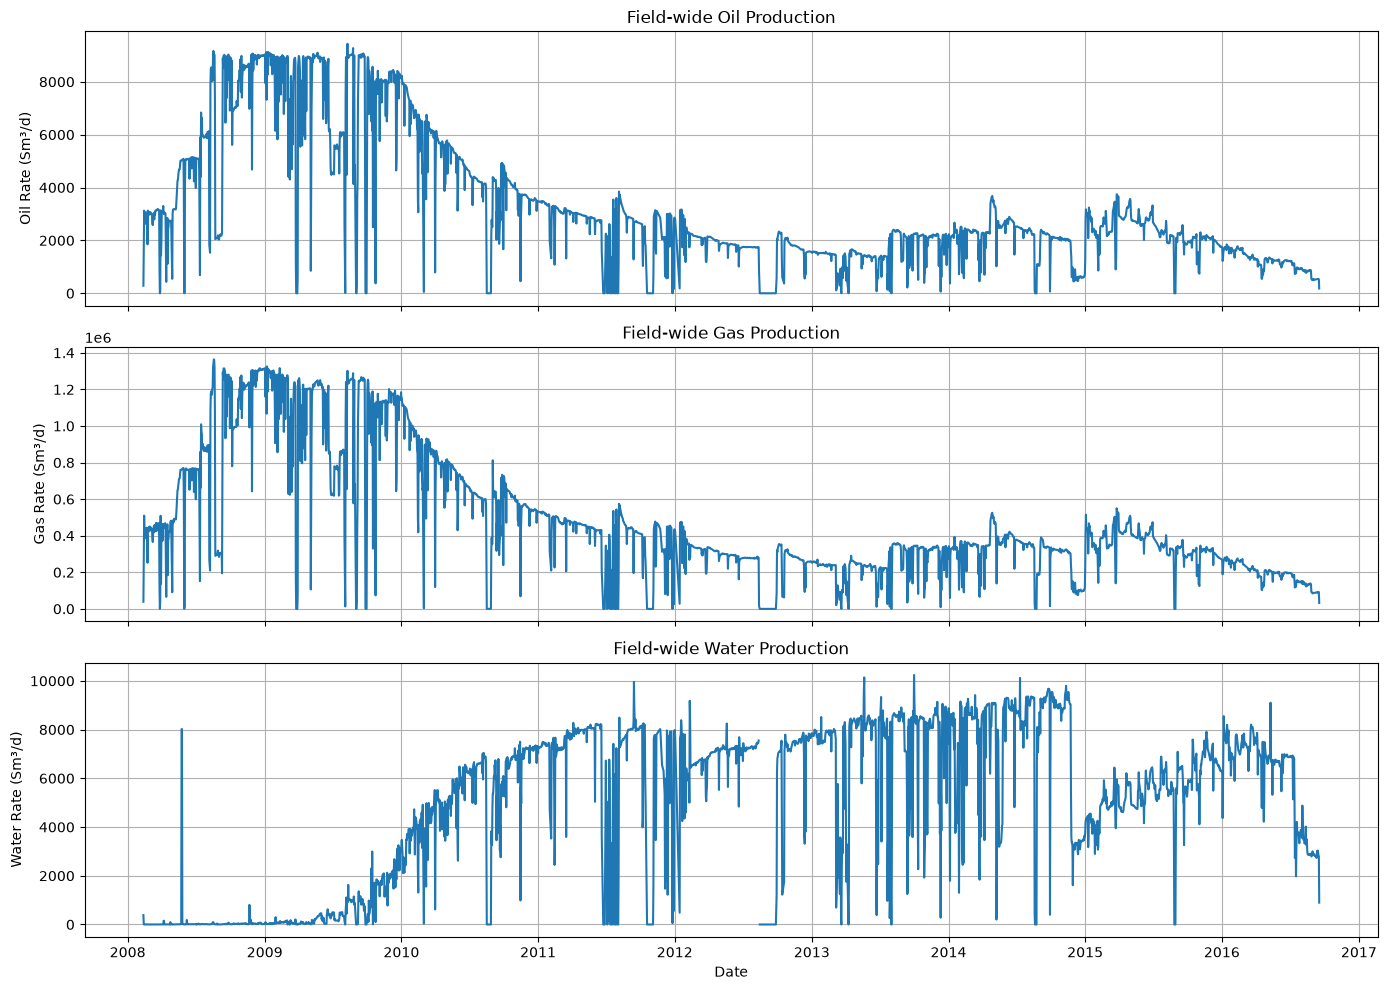

In [287]:
# This visualises the daily field-wide oil, gas and water production trends over time.
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

axes[0].plot(
    field_production['DATEPRD'],
    field_production['OIL_PRODUCTION']
)
axes[0].set_title('Field-wide Oil Production')
axes[0].set_ylabel('Oil Rate (Sm³/d)')
axes[0].grid(True)

axes[1].plot(
    field_production['DATEPRD'],
    field_production['GAS_PRODUCTION']
)
axes[1].set_title('Field-wide Gas Production')
axes[1].set_ylabel('Gas Rate (Sm³/d)')
axes[1].grid(True)

axes[2].plot(
    field_production['DATEPRD'],
    field_production['WATER_PRODUCTION']
)
axes[2].set_title('Field-wide Water Production')
axes[2].set_ylabel('Water Rate (Sm³/d)')
axes[2].set_xlabel('Date')
axes[2].grid(True)

plt.tight_layout()
plt.show()

**Purpose:** This plot shows the daily field-wide production volumes of oil, gas and water over time, providing an overview of the field's overall production history.

**Key Engineering Observations (Field-Wide Production):**
* **Plateau & Associated Gas Coupling:** Field oil production peaked at a plateau of ~9,000 Sm³/d in 2009 alongside ~1.3 × 10⁶ Sm³/d of associated gas, showing strong pressure coupling between oil and solution gas.
* **Inverse Oil-Water Shift:** From 2010 onward, declining oil rates were directly offset by rising water production (peaking near 9,500 Sm³/d in 2014), keeping total surface liquid throughput near separator design capacity throughout mid-to-late field life.
* **Operational Shut-Ins:** Intermittent downward spikes to zero reflect scheduled platform turnarounds, well testing, and temporary choke shut-ins.


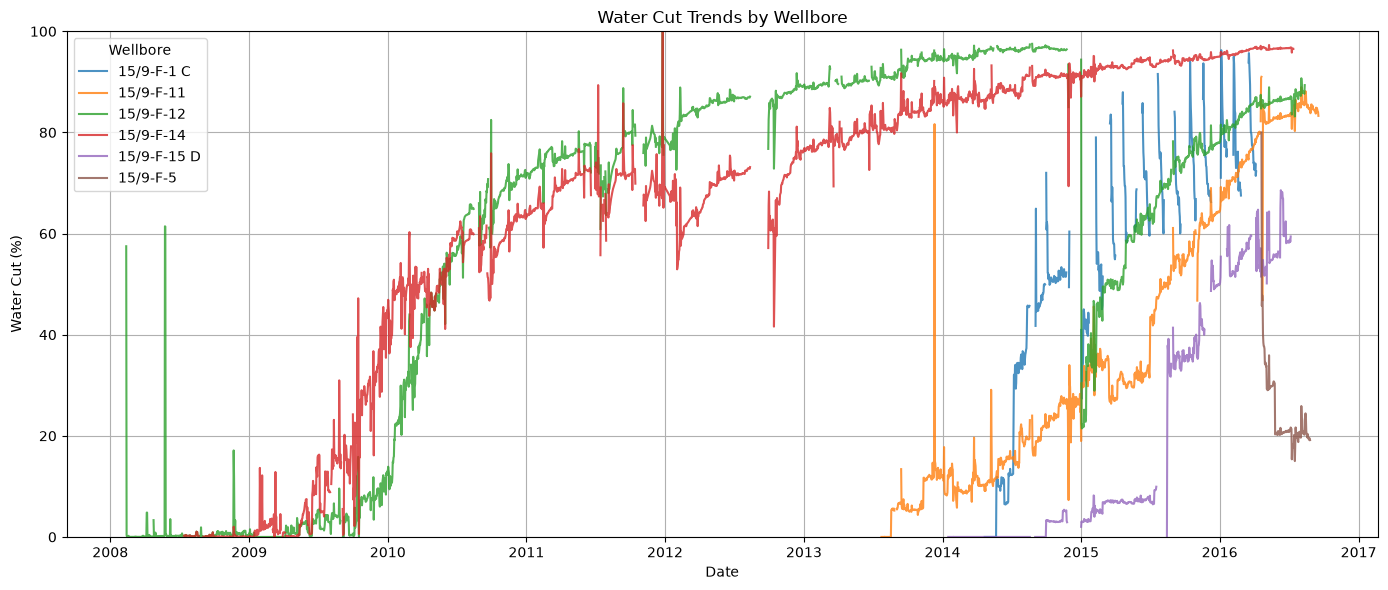

In [288]:
# This compares the water cut trends of individual producing wellbores over time.
plt.figure(figsize=(14, 6))

for well in df_analysis['NPD_WELL_BORE_NAME'].unique():
    well_data = df_analysis[
        df_analysis['NPD_WELL_BORE_NAME'] == well
    ]

    plt.plot(
        well_data['DATEPRD'],
        well_data['WATER_CUT'],
        label=well,
        alpha=0.8
    )

plt.title('Water Cut Trends by Wellbore')
plt.xlabel('Date')
plt.ylabel('Water Cut (%)')
plt.ylim(0, 100)
plt.legend(title='Wellbore')
plt.grid(True)
plt.tight_layout()
plt.show()

**Purpose:** This plot compares the percentage of water in total liquid production across individual wellbores over time, helping to identify changes in water production behaviour.

**Key Engineering Observations (Water Cut Trends):**
* **Water Breakthrough:** Early producers (`15/9-F-12` and `15/9-F-14`) produced dry oil from 2008 until late 2009, after which rapid water breakthrough drove water cuts above 70% by 2011 and >90% by 2015.
* **Infill Well Contributions:** Newer wells (`15/9-F-11`, `15/9-F-1 C`, and `15/9-F-15 D`) brought online between 2013 and 2015 initially produced lower water cuts, temporarily offsetting field-wide oil decline before experiencing water breakthrough themselves.
* **Facility Impact:** Rising field-wide water cut shifts the operational bottleneck from oil handling to surface separator liquid residence time and produced-water treatment capacity.


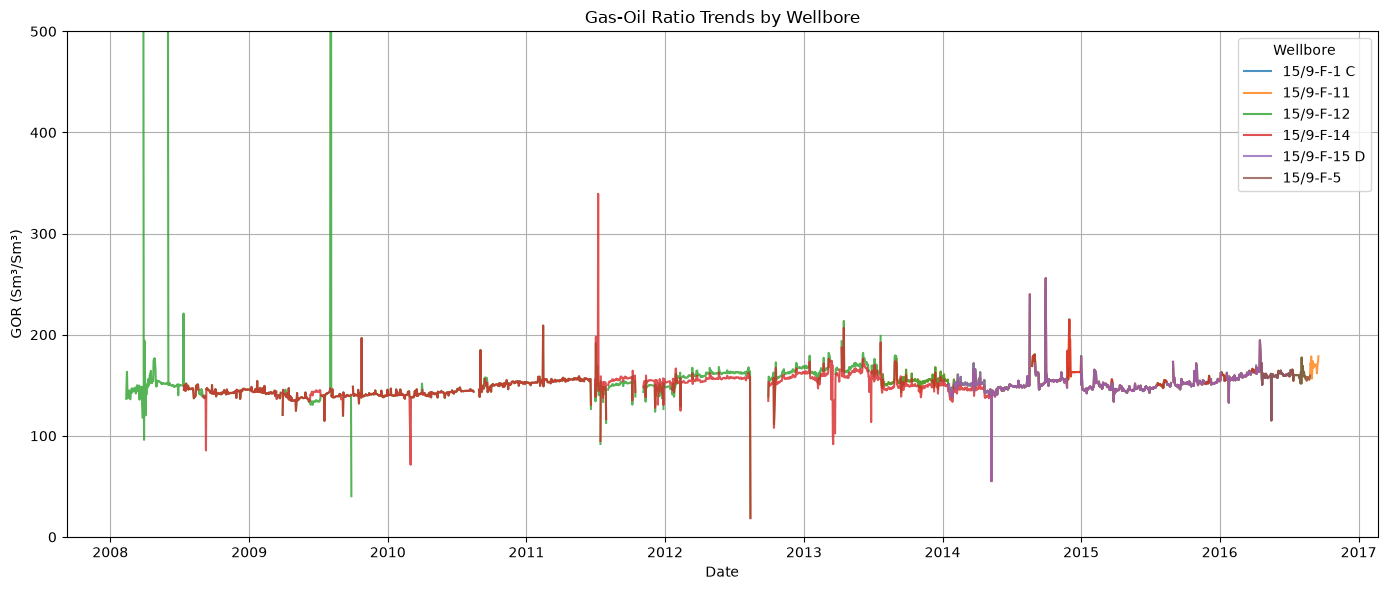

In [289]:
# This compares the gas-oil ratio trends of individual producing wellbores over time.
plt.figure(figsize=(14, 6))

for well in df_analysis['NPD_WELL_BORE_NAME'].unique():
    well_data = df_analysis[
        df_analysis['NPD_WELL_BORE_NAME'] == well
    ]

    plt.plot(
        well_data['DATEPRD'],
        well_data['GOR'],
        label=well,
        alpha=0.8
    )

plt.title('Gas-Oil Ratio Trends by Wellbore')
plt.xlabel('Date')
plt.ylabel('GOR (Sm³/Sm³)')
plt.ylim(0, 500)
plt.legend(title='Wellbore')
plt.grid(True)
plt.tight_layout()
plt.show()

**Purpose:** This plot compares the gas-oil ratio of individual wellbores over time, showing how gas production changes relative to oil production.

**Key Engineering Observations (Gas-Oil Ratio Trends):**
* **Effective Pressure Maintenance:** Producing GOR remained remarkably stable around **145–170 Sm³/Sm³** across all wellbores throughout the 8-year production history, confirming that water injection kept reservoir pressure above the bubble point and prevented free-gas breakthrough.
* **Predictable Gas-Handling Load:** Because GOR did not escalate late in field life, surface gas compression and conditioning systems experienced predictable gas-to-liquid ratios without gas-handling bottlenecks.
* **Transient Start-Up Spikes:** Isolated single-day spikes correspond to post-shutdown well restarts and flow-stabilization transients rather than sustained reservoir gas breakout.



## Section Summary

The production trend analysis involved three visualisations examining field-wide oil, gas and water production, as well as water cut and GOR trends across individual wellbores.

These plots provide an overview of production history, changes in produced fluid composition and variations in the behaviour of individual wells.

The observations provide a basis for investigating potential operational issues and flow assurance concerns in the next section.

## 5. Flow Assurance and Operational Surveillance

This stage involves examining production and operational parameters to identify potential flow assurance concerns and unusual well behaviour.

The analysis will focus on the relationship between oil production and choke size, using the Flow-to-Choke ratio as a simple operational surveillance indicator.

A 14-day rolling average will be used to identify significant drops in the ratio, which may indicate changes in well performance requiring further investigation.

The objective is to identify potential operational anomalies rather than confirm specific flow assurance problems.

In [290]:
# This calculates the oil production per percentage point of choke opening.
df_analysis['FLOW_TO_CHOKE'] = (
    df_analysis['BORE_OIL_VOL'] /
    df_analysis['AVG_CHOKE_SIZE_P']
)

# This excludes records with zero or missing choke size.
df_analysis.loc[
    df_analysis['AVG_CHOKE_SIZE_P'] <= 0, 'FLOW_TO_CHOKE'
] = np.nan

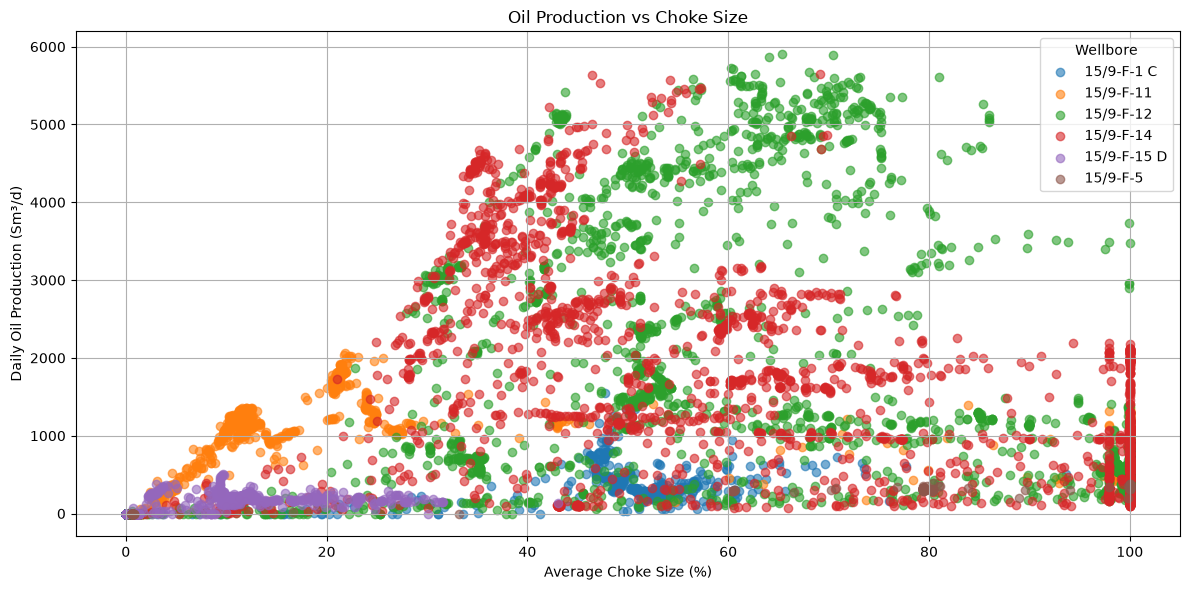

In [291]:
# This examines the relationship between oil production and choke size for each wellbore.
plt.figure(figsize=(12, 6))

for well in df_analysis['NPD_WELL_BORE_NAME'].unique():
    well_data = df_analysis[
        df_analysis['NPD_WELL_BORE_NAME'] == well
    ]

    plt.scatter(
        well_data['AVG_CHOKE_SIZE_P'],
        well_data['BORE_OIL_VOL'],
        label=well,
        alpha=0.6
    )

plt.title('Oil Production vs Choke Size')
plt.xlabel('Average Choke Size (%)')
plt.ylabel('Daily Oil Production (Sm³/d)')
plt.legend(title='Wellbore')
plt.grid(True)
plt.tight_layout()
plt.show()

**Purpose:** This plot examines the relationship between choke opening and oil production, helping to identify how changes in choke size relate to well output.

**Key Engineering Observations (Choke Performance & Flow Assurance):**
* **Choke-Limited vs. Reservoir-Limited Regimes:** During early plateau production (`15/9-F-12` and `15/9-F-14`), wells achieved 3,000–5,800 Sm³/d at moderate choke openings (35%–70%) to stay within surface separator limits. In late field life, chokes were opened to 100% while oil rates remained below 2,100 Sm³/d due to high water cut and declining reservoir energy.
* **Linear Critical Flow in New Wells:** Newer infill wells (`15/9-F-11`) exhibited a clean linear relationship between choke opening (0%–25%) and oil rate, reflecting healthy, unrestricted wellhead deliverability.
* **Flow Assurance Screening:** Low oil throughput despite moderate-to-wide choke openings (40%–80%) highlights high liquid-loading regimes and potential wellbore restrictions requiring routine pressure-temperature surveillance.


In [292]:
# This calculates the previous 14-day average Flow-to-Choke ratio separately for each well.
df_analysis['FLOW_TO_CHOKE_14D_AVG'] = np.nan

for well in df_analysis['NPD_WELL_BORE_NAME'].unique():

    well_index = df_analysis.index[
        df_analysis['NPD_WELL_BORE_NAME'] == well
    ]

    well_data = df_analysis.loc[well_index].sort_values('DATEPRD').copy()
    well_data['ROW_INDEX'] = well_data.index
    well_data = well_data.set_index('DATEPRD')

    rolling_average = well_data['FLOW_TO_CHOKE'].rolling(
        '14D',
        closed='left',
        min_periods=3
    ).mean()

    df_analysis.loc[
        well_data['ROW_INDEX'],
        'FLOW_TO_CHOKE_14D_AVG'
    ] = rolling_average.to_numpy()

In [293]:
# This flags days when the Flow-to-Choke ratio falls more than 20% below its previous 14-day average.
df_analysis['FLOW_TO_CHOKE_ANOMALY'] = (
    df_analysis['FLOW_TO_CHOKE'] <
    0.8 * df_analysis['FLOW_TO_CHOKE_14D_AVG']
)

# This displays the records identified as potential operational anomalies.
anomalies = df_analysis[
    df_analysis['FLOW_TO_CHOKE_ANOMALY']
]

anomalies[
    ['NPD_WELL_BORE_NAME', 'DATEPRD',
     'BORE_OIL_VOL', 'AVG_CHOKE_SIZE_P',
     'FLOW_TO_CHOKE', 'FLOW_TO_CHOKE_14D_AVG']
].head()

,NPD_WELL_BORE_NAME,DATEPRD,BORE_OIL_VOL,AVG_CHOKE_SIZE_P,FLOW_TO_CHOKE,FLOW_TO_CHOKE_14D_AVG
30,15/9-F-1 C,2014-05-07,925.31,47.920400,19.309313,24.516887
32,15/9-F-1 C,2014-05-09,176.80,29.133587,6.068597,23.190611
35,15/9-F-1 C,2014-05-12,769.01,46.933590,16.385067,20.580726
56,15/9-F-1 C,2014-06-02,459.83,41.713400,11.023556,15.812233
63,15/9-F-1 C,2014-06-09,238.45,38.978911,6.117410,14.852398


**Purpose:** This identifies significant reductions in the Flow-to-Choke ratio that may indicate changes in well performance and require further operational investigation.

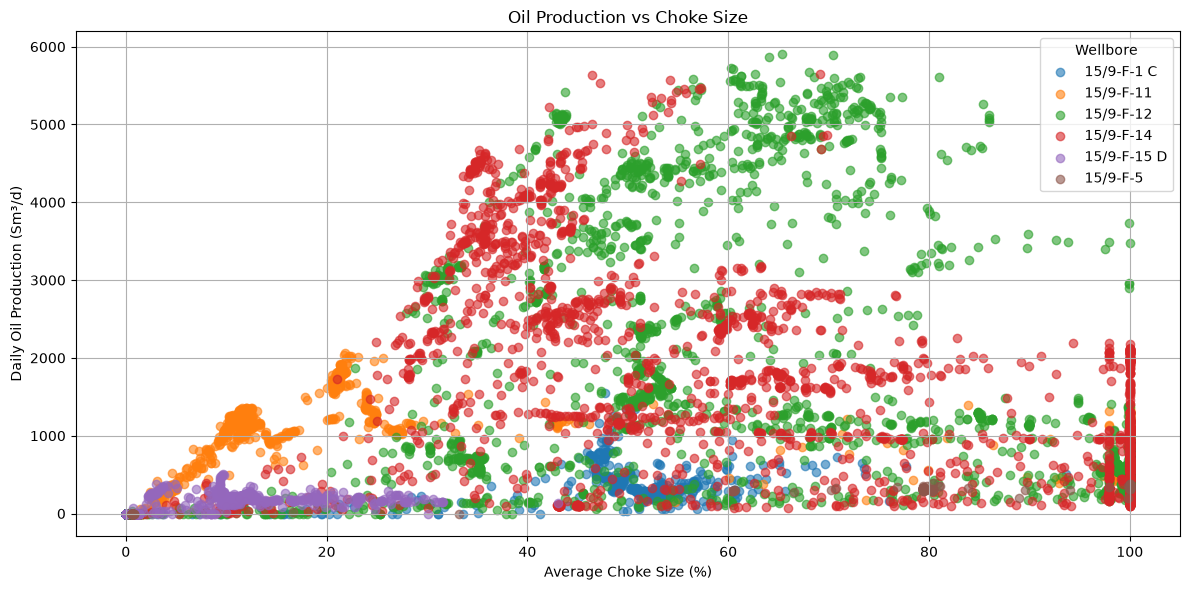

In [294]:
# This examines the relationship between oil production and choke size for each wellbore.
plt.figure(figsize=(12, 6))

for well in df_analysis['NPD_WELL_BORE_NAME'].unique():
    well_data = df_analysis[
        df_analysis['NPD_WELL_BORE_NAME'] == well
    ]

    plt.scatter(
        well_data['AVG_CHOKE_SIZE_P'],
        well_data['BORE_OIL_VOL'],
        label=well,
        alpha=0.6
    )

plt.title('Oil Production vs Choke Size')
plt.xlabel('Average Choke Size (%)')
plt.ylabel('Daily Oil Production (Sm³/d)')
plt.legend(title='Wellbore')
plt.grid(True)
plt.tight_layout()
plt.show()

**Purpose:** This plot examines how choke opening relates to oil production across individual wellbores, helping to identify variations in well output at different choke settings.

In [295]:
# This calculates the previous 14-day average Flow-to-Choke ratio separately for each well.
df_analysis['FLOW_TO_CHOKE_14D_AVG'] = np.nan

for well in df_analysis['NPD_WELL_BORE_NAME'].unique():

    well_index = df_analysis.index[
        df_analysis['NPD_WELL_BORE_NAME'] == well
    ]

    well_data = df_analysis.loc[well_index].sort_values('DATEPRD').copy()
    well_data['ROW_INDEX'] = well_data.index
    well_data = well_data.set_index('DATEPRD')

    rolling_average = well_data['FLOW_TO_CHOKE'].rolling(
        '14D',
        closed='left',
        min_periods=3
    ).mean()

    df_analysis.loc[
        well_data['ROW_INDEX'],
        'FLOW_TO_CHOKE_14D_AVG'
    ] = rolling_average.to_numpy()

In [296]:
# This compares the daily Flow-to-Choke ratio with its previous 14-day average.
df_analysis[
    ['NPD_WELL_BORE_NAME', 'DATEPRD',
     'FLOW_TO_CHOKE', 'FLOW_TO_CHOKE_14D_AVG']
].head(10)

,NPD_WELL_BORE_NAME,DATEPRD,FLOW_TO_CHOKE,FLOW_TO_CHOKE_14D_AVG
0,15/9-F-1 C,2014-04-07,NaN,NaN
1,15/9-F-1 C,2014-04-08,0.0,NaN
2,15/9-F-1 C,2014-04-09,0.0,NaN
3,15/9-F-1 C,2014-04-10,0.0,NaN
4,15/9-F-1 C,2014-04-11,0.0,0.0
5,15/9-F-1 C,2014-04-12,0.0,0.0
6,15/9-F-1 C,2014-04-13,0.0,0.0
7,15/9-F-1 C,2014-04-14,NaN,0.0
8,15/9-F-1 C,2014-04-15,0.0,0.0
9,15/9-F-1 C,2014-04-16,NaN,0.0


In [297]:
# This identifies days when the Flow-to-Choke ratio drops more than 20% below its rolling average.
df_analysis['FLOW_TO_CHOKE_ANOMALY'] = (
    df_analysis['FLOW_TO_CHOKE'] <
    0.8 * df_analysis['FLOW_TO_CHOKE_14D_AVG']
)

In [298]:
# This counts the potential operational anomalies identified across the wellbores.
df_analysis['FLOW_TO_CHOKE_ANOMALY'].value_counts()

FLOW_TO_CHOKE_ANOMALY
False    8254
True      907
Name: count, dtype: int64

In [299]:
# This displays the wellbore records identified as potential operational anomalies.
anomalies = df_analysis[
    df_analysis['FLOW_TO_CHOKE_ANOMALY']
]

anomalies[
    ['NPD_WELL_BORE_NAME', 'DATEPRD',
     'BORE_OIL_VOL', 'AVG_CHOKE_SIZE_P',
     'FLOW_TO_CHOKE', 'FLOW_TO_CHOKE_14D_AVG']
].head(10)

,NPD_WELL_BORE_NAME,DATEPRD,BORE_OIL_VOL,AVG_CHOKE_SIZE_P,FLOW_TO_CHOKE,FLOW_TO_CHOKE_14D_AVG
30,15/9-F-1 C,2014-05-07,925.31,47.920400,19.309313,24.516887
32,15/9-F-1 C,2014-05-09,176.80,29.133587,6.068597,23.190611
35,15/9-F-1 C,2014-05-12,769.01,46.933590,16.385067,20.580726
56,15/9-F-1 C,2014-06-02,459.83,41.713400,11.023556,15.812233
63,15/9-F-1 C,2014-06-09,238.45,38.978911,6.117410,14.852398
80,15/9-F-1 C,2014-06-26,369.83,44.000000,8.405227,15.201535
81,15/9-F-1 C,2014-06-27,418.45,44.375104,9.429837,14.622103
104,15/9-F-1 C,2014-07-20,290.87,43.933952,6.620620,10.452636
126,15/9-F-1 C,2014-08-11,351.80,49.437113,7.116111,9.253860
127,15/9-F-1 C,2014-08-12,287.03,48.828244,5.878360,9.074989


**Purpose:** This identifies significant reductions in the Flow-to-Choke ratio that may indicate changes in well performance and require further operational investigation.

## Section Summary

The flow assurance and operational surveillance analysis examined the relationship between oil production and choke size across the producing wellbores.

A Flow-to-Choke ratio was calculated for each production record, and a 14-day rolling average was used as a reference for identifying significant changes in well performance.

Records showing a reduction of more than 20% below the previous rolling average were flagged as potential operational anomalies.

These observations provide an initial basis for identifying unusual production behaviour that may require further investigation.

## 6.Production Decline Analysis and Forecasting

This stage involves analysing the historical oil production performance of a selected wellbore to understand its decline behaviour.

An exponential decline model will be applied to the selected production period to estimate the decline rate and forecast oil production over the next six months.

The analysis will provide an understanding of the well's production trend and demonstrate how historical production data can be used for forecasting.

I Will use well 15/9-F-14. The monthly production data will be calculated using total oil produced divided by the total operating days. This accounts for differences in operating hours between months.

In [300]:
# This selects well 15/9-F-14 and prepares its monthly oil production data.
well_data = df_analysis[
    df_analysis['NPD_WELL_BORE_NAME'] == '15/9-F-14'
].copy()

well_data['MONTH'] = well_data['DATEPRD'].dt.to_period('M')

monthly_well = well_data.groupby('MONTH').agg(
    OIL_VOLUME=('BORE_OIL_VOL', 'sum'),
    ON_STREAM_HRS=('ON_STREAM_HRS', 'sum')
).reset_index()

# This calculates the average oil production rate during operating hours.
monthly_well['OIL_RATE'] = (
    monthly_well['OIL_VOLUME'] /
    (monthly_well['ON_STREAM_HRS'] / 24)
)

# This excludes months with insufficient operating hours or no oil production.
monthly_well = monthly_well[
    (monthly_well['ON_STREAM_HRS'] > 300) &
    (monthly_well['OIL_RATE'] > 0)
]

In [301]:
# This displays the prepared monthly production data for the selected well.
monthly_well.head()

,MONTH,OIL_VOLUME,ON_STREAM_HRS,OIL_RATE
5,2008-07,51285.08,437.57000,2812.902896
6,2008-08,67621.20,458.40000,3540.376963
7,2008-09,114596.26,642.70833,4279.250963
8,2008-10,142817.06,742.50000,4616.309010
9,2008-11,104409.61,717.83333,3490.825147


I will use January 2013 to July 2016, this is a period that shows a relatively consistent decline in the selected well's production.

In [302]:
# This selects the production records within the chosen decline period.
decline_data = monthly_well[
    (monthly_well['MONTH'] >= pd.Period('2013-01', freq='M')) &
    (monthly_well['MONTH'] <= pd.Period('2016-07', freq='M'))
].copy()

decline_data = decline_data.reset_index(drop=True)

# This assigns a monthly time value for the decline analysis.
decline_data['TIME_MONTHS'] = np.arange(len(decline_data))

In [303]:
# This displays the beginning and end of the selected decline period.
decline_data[
    ['MONTH', 'OIL_RATE', 'TIME_MONTHS']
].head(), decline_data.tail()

(     MONTH    OIL_RATE  TIME_MONTHS
 0  2013-01  973.703226            0
 1  2013-02  955.647237            1
 2  2013-03  888.441858            2
 3  2013-04  985.065939            3
 4  2013-05  905.080724            4,
       MONTH  OIL_VOLUME  ON_STREAM_HRS    OIL_RATE  TIME_MONTHS
 38  2016-03     3753.80      737.66666  122.129960           38
 39  2016-04     3112.41      715.83333  104.350883           39
 40  2016-05     3212.96      738.00000  104.486504           40
 41  2016-06     3075.03      716.08333  103.061637           41
 42  2016-07     1326.86      301.22500  105.717122           42)

The exponential decline model is expressed as:

$$
q(t) = q_i e^{-Dt}
$$

Where:
* $q(t)$ = oil production rate at time $t$
* $q_i$ = initial production rate
* $D$ = exponential decline constant
* $t$ = time in months

We will use `np.polyfit()` to fit a straight line to the natural logarithm of the production rates.


In [304]:
# This fits an exponential decline model to the selected production data.
decline_coefficients = np.polyfit(
    decline_data['TIME_MONTHS'],
    np.log(decline_data['OIL_RATE']),
    1
)

# This extracts the decline constant and initial production rate.
decline_rate = -decline_coefficients[0]
initial_rate = np.exp(decline_coefficients[1])

# This calculates the fitted production rates.
decline_data['FITTED_RATE'] = np.exp(
    np.polyval(
        decline_coefficients,
        decline_data['TIME_MONTHS']
    )
)

# This evaluates how well the model fits the historical production data.
log_actual = np.log(decline_data['OIL_RATE'])
log_fitted = np.log(decline_data['FITTED_RATE'])

r_squared = 1 - (
    ((log_actual - log_fitted) ** 2).sum() /
    ((log_actual - log_actual.mean()) ** 2).sum()
)

print('Initial Production Rate:', round(initial_rate, 2), 'Sm³/operating day')
print('Decline Constant:', round(decline_rate, 4), 'per month')
print('R-squared:', round(r_squared, 4))

Initial Production Rate: 1123.48 Sm³/operating day
Decline Constant: 0.0568 per month
R-squared: 0.9897


In [305]:
# This generates the next six monthly production forecasts using the fitted decline model.
forecast_time = np.arange(
    len(decline_data),
    len(decline_data) + 6
)

forecast_rate = np.exp(
    decline_coefficients[1] +
    decline_coefficients[0] * forecast_time
)

forecast_months = pd.period_range(
    start=decline_data['MONTH'].iloc[-1] + 1,
    periods=6,
    freq='M'
)

forecast_data = pd.DataFrame({
    'MONTH': forecast_months,
    'FORECAST_OIL_RATE': forecast_rate
})

forecast_data

,MONTH,FORECAST_OIL_RATE
0,2016-08,97.825047
1,2016-09,92.426433
2,2016-10,87.325749
3,2016-11,82.506554
4,2016-12,77.953313
5,2017-01,73.651349


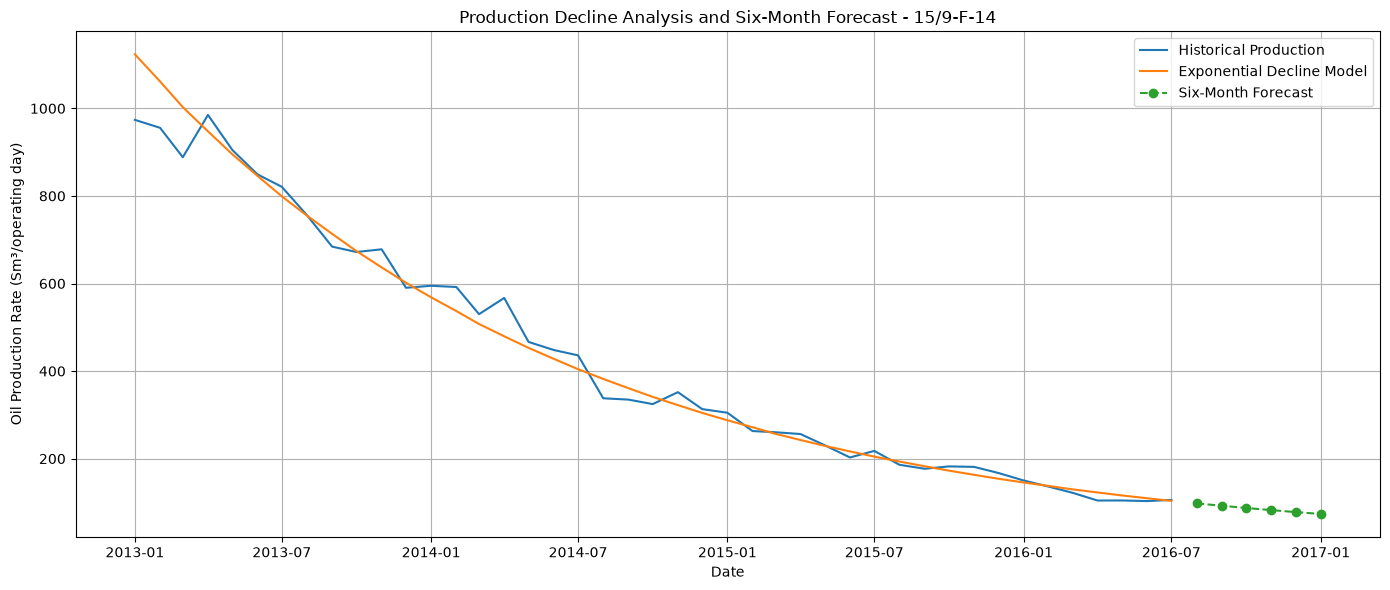

In [306]:
# This compares historical oil production with the fitted decline curve and six-month forecast.
plt.figure(figsize=(14, 6))

plt.plot(
    decline_data['MONTH'].dt.to_timestamp(),
    decline_data['OIL_RATE'],
    label='Historical Production'
)

plt.plot(
    decline_data['MONTH'].dt.to_timestamp(),
    decline_data['FITTED_RATE'],
    label='Exponential Decline Model'
)

plt.plot(
    forecast_data['MONTH'].dt.to_timestamp(),
    forecast_data['FORECAST_OIL_RATE'],
    linestyle='--',
    marker='o',
    label='Six-Month Forecast'
)

plt.title('Production Decline Analysis and Six-Month Forecast - 15/9-F-14')
plt.xlabel('Date')
plt.ylabel('Oil Production Rate (Sm³/operating day)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Purpose:** This plot compares the historical oil production trend with the fitted exponential decline model and its six-month forecast, illustrating the expected future production behaviour of the selected well.

**Key Engineering Observations (Production Decline):**

- **Production Decline:** Well 15/9-F-14 experienced a sustained reduction in oil production during the selected analysis period.
- **Decline Modelling:** The exponential decline model provides a close representation of the historical production trend.
- **Forecasting:** The six-month forecast indicates a continued reduction in the well's expected oil production rate if the observed decline behaviour persists.

## Section Summary

The production decline analysis focused on well 15/9-F-14 using historical production data from January 2013 to July 2016.

Monthly oil production rates were calculated using the recorded operating hours, and an exponential decline model was fitted to the selected production period.

The fitted model was used to estimate the decline constant and forecast oil production over the following six months. The historical production data, fitted model and forecast were presented in a single plot.

The analysis demonstrates how historical production trends can support production forecasting and operational planning.

## 7.Final Results, Export and Engineering Recommendations

This final stage summarises the key findings from the production performance, trend analysis, flow assurance and production forecasting.

The observations will be used to highlight important production behaviour and potential operational concerns in the Volve field.

The prepared dataset will also be exported as a CSV file for future analysis and reference.

### Key Engineering Findings

- **Production Performance:** Water cut and GOR analysis provided insights into changes in produced fluid composition and the performance of individual wellbores.

- **Water Handling:** Increasing water production can place additional demands on surface separation and produced-water treatment facilities.

- **Operational Surveillance:** The Flow-to-Choke analysis identified potential changes in well performance that may require further investigation.

- **Production Forecasting:** Exponential decline analysis demonstrated how historical production data can be used to estimate future well production.

In [309]:
df_analysis.to_csv('cleaned_volve.csv', index=False)

print("Dataset successfully exported as cleaned_volve.csv")

Dataset successfully exported as cleaned_volve.csv


In [310]:
exported_data = pd.read_csv('cleaned_volve.csv')

print("Dataset shape:", exported_data.shape)
exported_data.head()

Dataset shape: (9161, 34)


,DATEPRD,WELL_BORE_CODE,NPD_WELL_BORE_CODE,NPD_WELL_BORE_NAME,NPD_FIELD_CODE,NPD_FIELD_NAME,NPD_FACILITY_CODE,NPD_FACILITY_NAME,ON_STREAM_HRS,AVG_DOWNHOLE_PRESSURE,...,NEGATIVE_WATER_FLAG,ON_STREAM_GT_24_FLAG,BORE_WAT_VOL_ANALYSIS,TOTAL_LIQUID,WATER_CUT,GOR,OPERATING_EFFICIENCY,FLOW_TO_CHOKE,FLOW_TO_CHOKE_14D_AVG,FLOW_TO_CHOKE_ANOMALY
0,2014-04-07,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,0.00000,...,False,False,0.0,0.0,NaN,NaN,0.0,NaN,NaN,False
1,2014-04-08,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,NaN,...,False,False,0.0,0.0,NaN,NaN,0.0,0.0,NaN,False
2,2014-04-09,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,NaN,...,False,False,0.0,0.0,NaN,NaN,0.0,0.0,NaN,False
3,2014-04-10,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,NaN,...,False,False,0.0,0.0,NaN,NaN,0.0,0.0,NaN,False
4,2014-04-11,NO 15/9-F-1 C,7405,15/9-F-1 C,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,310.37614,...,False,False,0.0,0.0,NaN,NaN,0.0,0.0,0.0,False


## Section Summary

The final stage summarised the key findings from the production performance, trend analysis, operational surveillance and production forecasting.

The analysis highlighted changes in produced fluid composition, increasing water-handling requirements, potential operational anomalies and the application of exponential decline modelling for production forecasting.

The prepared production dataset, containing the original records and calculated engineering indicators, was exported as `cleaned_volve.csv` for future use.

This completes the Python-based analysis of the Volve offshore oil and gas production dataset.